# Backtest 1 · Gold/silver PCA residual strategy (hourly, 2019 – 2026)

Model refit every 24 hours on the previous 480 hours (no look-ahead): PCA on gold, silver, dollar index → PC3 portfolio (long silver / short gold) → Ornstein–Uhlenbeck s-score. Sell the spread at s > +2, buy at s < −2, exit at ±0.5, stop at ±4, time stop 96 hours. Costs: demo spread × 1.5 + $6 per lot. Includes a prop-firm challenge simulation and a parameter sensitivity grid.

In [1]:
import sys
sys.path.insert(0, "../src")   # shared code lives in src/; data in ../data (see README)
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)

In [2]:
%run ../src/pca_strategy.py

Data: 2019-01-01 -> 2026-09-29, 45,421 hourly bars
Params: Params(window=480, step=24, entry=2.0, exit=0.5, stop=4.0, max_hl=48.0, max_hold=96, target_vol=0.1, max_lev=10.0, spread_mult=1.5, commission=6.0, flat_weekend=False)

=== Backtest (base parameters, costs = demo spread x1.5 + $6/lot) ===
CAGR %                  -2.321
Sharpe                  -0.609
Sharpe before costs     -0.279
max DD %               -18.821
trades                 104.000
trades/month             1.126
win %                   52.885
avg hold (h)            51.779
avg gross/trade %       -0.077
avg cost/trade %         0.091

per year:
          net return %  gross (no costs) %  trades
time_utc                                          
2019             -0.28                1.83       9
2020             -5.28               -3.92      17
2021              1.43                3.08      16
2022             -0.33                1.78      22
2023             -3.81               -2.90       9
2024             -0.36  

  no costs                       Sharpe  -0.28   CAGR  -1.11%   maxDD -13.16%


  demo spread, no commission     Sharpe  -0.48   CAGR  -1.86%   maxDD -16.50%


  base: spread x1.5 + $6         Sharpe  -0.61   CAGR  -2.32%   maxDD -18.82%


  harsh: spread x3 + $7          Sharpe  -0.92   CAGR  -3.45%   maxDD -25.06%

=== Prop challenge simulation (target +8%, daily loss 5%, max loss 10%, 120 trading days) ===


  risk x1 (vol target 10%): 374 attempts | unfinished 100%


  risk x2 (vol target 20%): 374 attempts | unfinished 92% | fail: max loss 6% | pass 1% | median days to pass 107


  risk x3 (vol target 30%): 374 attempts | unfinished 56% | fail: max loss 20% | fail: daily loss 14% | pass 10% | median days to pass 44


  risk x4 (vol target 40%): 374 attempts | fail: daily loss 35% | unfinished 30% | pass 22% | fail: max loss 13% | median days to pass 37

=== Sensitivity grid: Sharpe after costs (window x entry) ===
    (for robustness only: picking the best cell would be curve-fitting)


                        1.5          2.0          2.5
window \ entry                                       
240             -1.19 (405)  -1.17 (266)  -1.15 (182)
480             -0.50 (167)  -0.61 (104)   -0.50 (69)
960              -0.60 (28)   -0.87 (17)   -0.31 (14)


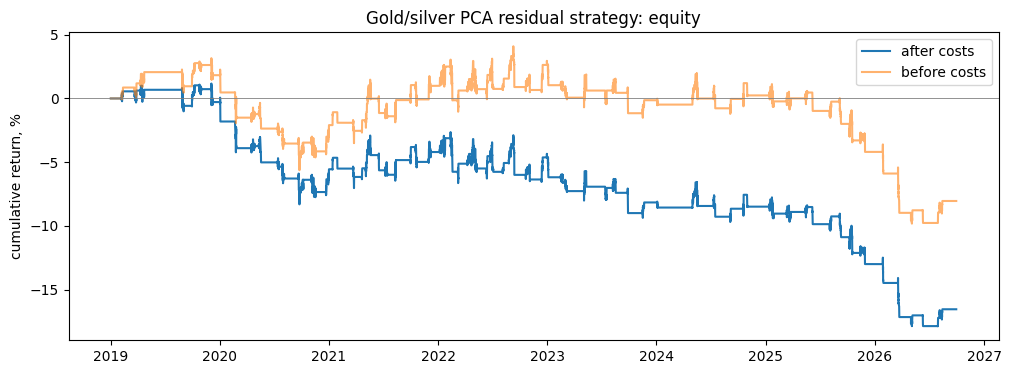

In [3]:
eq = pd.read_csv("../data/backtest/equity.csv", index_col=0, parse_dates=True)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(eq.index, (1 + eq["ret"]).cumprod() * 100 - 100, label="after costs")
ax.plot(eq.index, eq["gross"].cumsum() * 100, label="before costs", alpha=0.6)
ax.axhline(0, color="grey", lw=0.6)
ax.set_ylabel("cumulative return, %")
ax.set_title("Gold/silver PCA residual strategy: equity")
ax.legend()
plt.show()

**Result:** negative after costs (Sharpe −0.61) and even before costs. The silver-vs-gold leftover trends instead of pulling back (see `pca/01`).